This project explores the relationship between generative AI usage, academic performance,
traditional study habits, skill retention, and student burnout risk.

The goal is to identify patterns in the dataset, communicate findings through visualizations,
and develop evidence-based recommendations while recognizing the limitations of observational data.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from IPython.display import display

sns.set_theme(style="whitegrid", palette="deep")

uploaded = files.upload()

Saving ai_student_impact_dataset (1).csv to ai_student_impact_dataset (1).csv


In [3]:
file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
display(df.head())

Rows: 50,000
Columns: 16


,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium


pandas nos permite analizar datos tabulares.

NumPy nos ayudará con operaciones numéricas.

Matplotlib y Seaborn servirán para las visualizaciones.

files.upload() permite cargar el archivo desde tu computadora.

df.head() muestra los primeros cinco registros.

In [4]:
print("Dataset shape:", df.shape)

print("\nData types:")
display(df.dtypes.to_frame("Data type"))

print("\nMissing values:")
display(
    df.isnull()
      .sum()
      .sort_values(ascending=False)
      .to_frame("Missing values")
)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nUnique student IDs:", df["Student_ID"].nunique())

Dataset shape: (50000, 16)

Data types:


,Data type
Student_ID,int64
Major_Category,object
Year_of_Study,object
Pre_Semester_GPA,float64
Weekly_GenAI_Hours,float64
Primary_Use_Case,object
Prompt_Engineering_Skill,object
Tool_Diversity,int64
Paid_Subscription,bool
Traditional_Study_Hours,float64



Missing values:


,Missing values
Student_ID,0
Major_Category,0
Year_of_Study,0
Pre_Semester_GPA,0
Weekly_GenAI_Hours,0
Primary_Use_Case,0
Prompt_Engineering_Skill,0
Tool_Diversity,0
Paid_Subscription,0
Traditional_Study_Hours,0



Duplicate rows: 0

Unique student IDs: 50000


los tipos de variables, los valores faltantes y los posibles duplicados.

In [5]:
# Revisar las variables numéricas
display(df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Student_ID,50000.0,125000.50,14433.90,100001.00,112500.75,125000.50,137500.25,150000.00
Pre_Semester_GPA,50000.0,3.15,0.48,1.18,2.83,3.21,3.52,4.00
Weekly_GenAI_Hours,50000.0,8.43,8.27,0.00,2.39,5.80,11.72,40.00
Tool_Diversity,50000.0,2.80,1.19,1.00,2.00,3.00,4.00,5.00
Traditional_Study_Hours,50000.0,11.21,5.16,1.00,7.56,11.18,14.71,35.86
Perceived_AI_Dependency,50000.0,3.51,1.82,1.00,2.00,3.00,5.00,10.00
Anxiety_Level_During_Exams,50000.0,4.27,2.14,1.00,3.00,4.00,6.00,10.00
Post_Semester_GPA,50000.0,3.35,0.50,1.00,3.02,3.42,3.75,4.00
Skill_Retention_Score,50000.0,75.80,13.28,10.78,66.82,76.00,85.19,100.00


describe() nos muestra estadísticas como la media, desviación estándar, mínimo, máximo y cuartiles

In [6]:
# Revisar las variables de texto
for col in df.select_dtypes(include="object").columns:
    print(f"\n{col}")
    print(df[col].value_counts().head(10))


Major_Category
Major_Category
STEM          15059
Business      12538
Humanities     9994
Medical        6476
Arts           5933
Name: count, dtype: int64

Year_of_Study
Year_of_Study
Junior       11045
Freshman     11031
Senior       10634
Sophomore     9860
Graduate      7430
Name: count, dtype: int64

Primary_Use_Case
Primary_Use_Case
Debugging/Troubleshooting    12295
Copywriting/Drafting         12011
Ideation                     10721
Summarizing_Reading           8633
Direct_Answer_Generation      6340
Name: count, dtype: int64

Prompt_Engineering_Skill
Prompt_Engineering_Skill
Beginner        18495
Intermediate    17696
Advanced        13809
Name: count, dtype: int64

Institutional_Policy
Institutional_Policy
Allowed_With_Citation    25224
Actively_Encouraged      14988
Strict_Ban                9788
Name: count, dtype: int64

Burnout_Risk_Level
Burnout_Risk_Level
Medium    21144
Low       16369
High      12487
Name: count, dtype: int64


In [7]:
variables = [
    "Student_ID",
    "Weekly_GenAI_Hours",
    "Pre_Semester_GPA",
    "Post_Semester_GPA",
    "Traditional_Study_Hours",
    "Skill_Retention_Score",
    "Perceived_AI_Dependency",
    "Anxiety_Level_During_Exams",
    "Burnout_Risk_Level"
]

faltantes = [col for col in variables if col not in df.columns]

if faltantes:
    print("Revisa los nombres de estas columnas:", faltantes)
else:
    print("Todas las variables necesarias están disponibles.")

Todas las variables necesarias están disponibles.


In [8]:
df["GPA_Change"] = (
    df["Post_Semester_GPA"] - df["Pre_Semester_GPA"]
)

display(
    df[
        [
            "Pre_Semester_GPA",
            "Post_Semester_GPA",
            "GPA_Change"
        ]
    ].head()
)

,Pre_Semester_GPA,Post_Semester_GPA,GPA_Change
0,2.418,2.393,-0.025
1,3.821,3.696,-0.125
2,3.398,3.499,0.101
3,3.789,4.000,0.211
4,3.635,3.798,0.163


In [9]:
indicadores = pd.Series({
    "Promedio inicial": df["Pre_Semester_GPA"].mean(),
    "Promedio final": df["Post_Semester_GPA"].mean(),
    "Cambio medio del GPA": df["GPA_Change"].mean(),
    "Horas semanales de IA": df["Weekly_GenAI_Hours"].mean(),
    "Horas de estudio tradicional": df["Traditional_Study_Hours"].mean(),
    "Retención media de habilidades": df["Skill_Retention_Score"].mean()
})

display(indicadores.round(2).to_frame("Valor"))

,Valor
Promedio inicial,3.15
Promedio final,3.35
Cambio medio del GPA,0.20
Horas semanales de IA,8.43
Horas de estudio tradicional,11.21
Retención media de habilidades,75.80


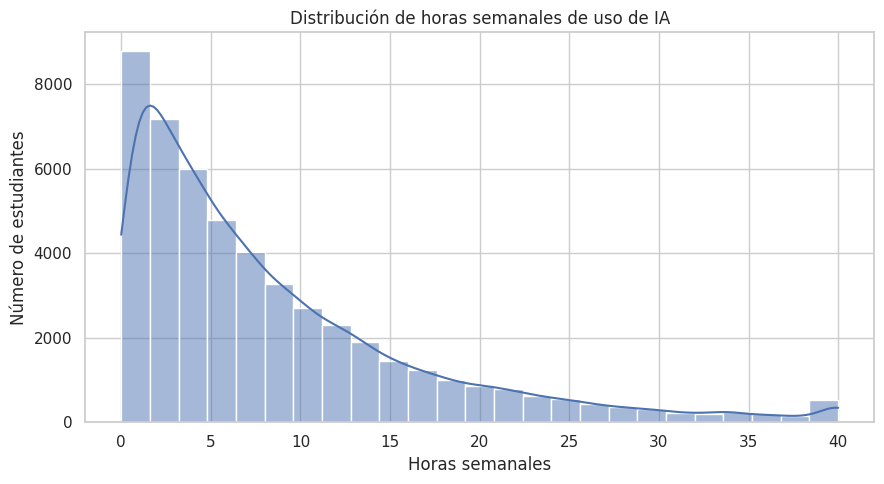

In [10]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Weekly_GenAI_Hours",
    bins=25,
    kde=True
)

plt.title("Distribución de horas semanales de uso de IA")
plt.xlabel("Horas semanales")
plt.ylabel("Número de estudiantes")
plt.tight_layout()
plt.show()

Este histograma permite observar si la mayoría de los estudiantes utiliza IA pocas horas, muchas horas o si el uso se distribuye de otra manera.

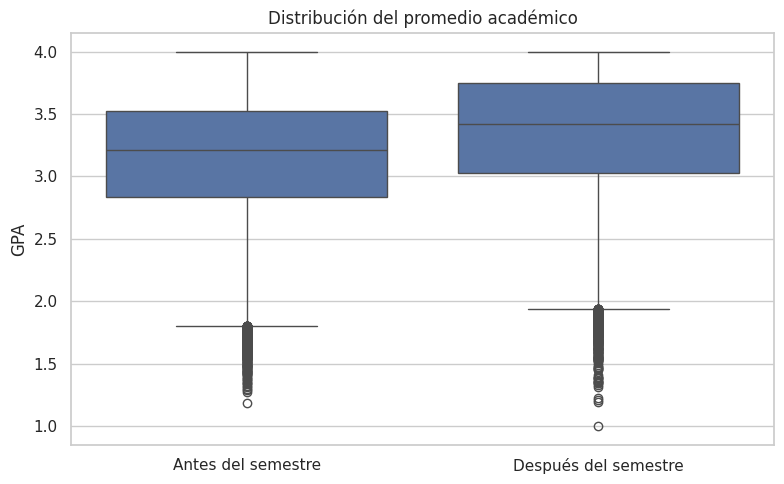

In [11]:
gpa = df[["Pre_Semester_GPA", "Post_Semester_GPA"]].melt(
    var_name="Periodo",
    value_name="GPA"
)

gpa["Periodo"] = gpa["Periodo"].replace({
    "Pre_Semester_GPA": "Antes del semestre",
    "Post_Semester_GPA": "Después del semestre"
})

plt.figure(figsize=(8, 5))

sns.boxplot(data=gpa, x="Periodo", y="GPA")

plt.title("Distribución del promedio académico")
plt.xlabel("")
plt.ylabel("GPA")
plt.tight_layout()
plt.show()

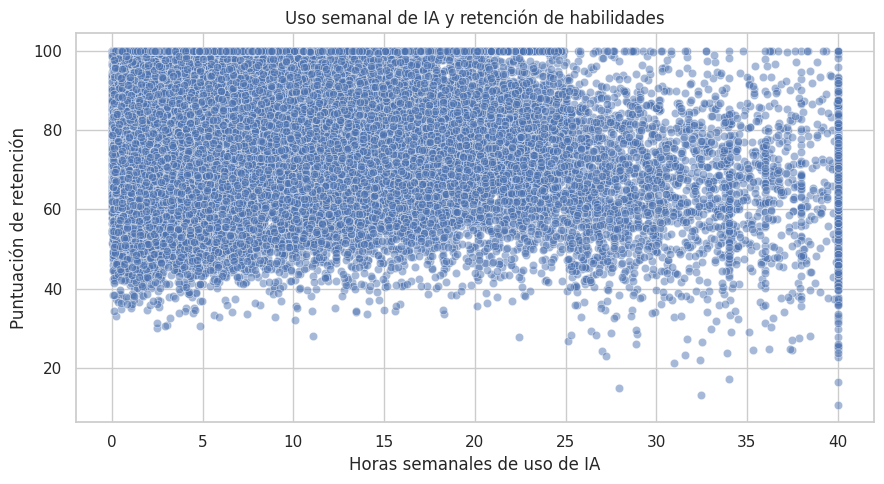

In [12]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Weekly_GenAI_Hours",
    y="Skill_Retention_Score",
    alpha=0.5
)

plt.title("Uso semanal de IA y retención de habilidades")
plt.xlabel("Horas semanales de uso de IA")
plt.ylabel("Puntuación de retención")
plt.tight_layout()
plt.show()

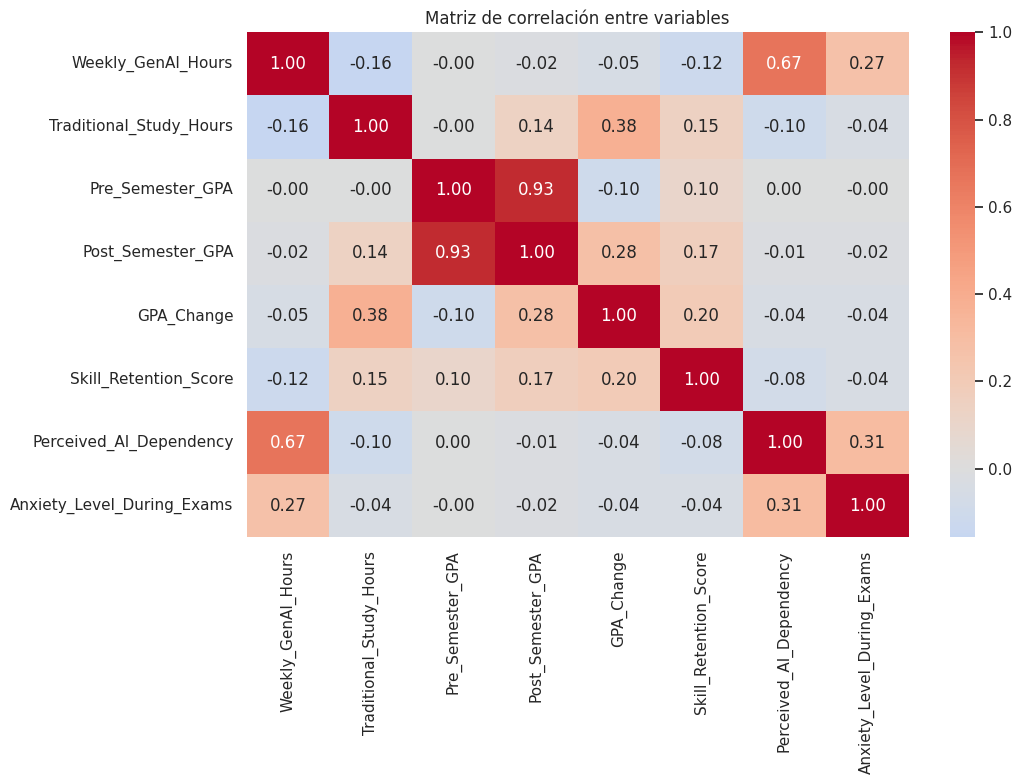

In [13]:
columnas_correlacion = [
    "Weekly_GenAI_Hours",
    "Traditional_Study_Hours",
    "Pre_Semester_GPA",
    "Post_Semester_GPA",
    "GPA_Change",
    "Skill_Retention_Score",
    "Perceived_AI_Dependency",
    "Anxiety_Level_During_Exams"
]

correlaciones = df[columnas_correlacion].corr(numeric_only=True)

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlaciones,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Matriz de correlación entre variables")
plt.tight_layout()
plt.show()

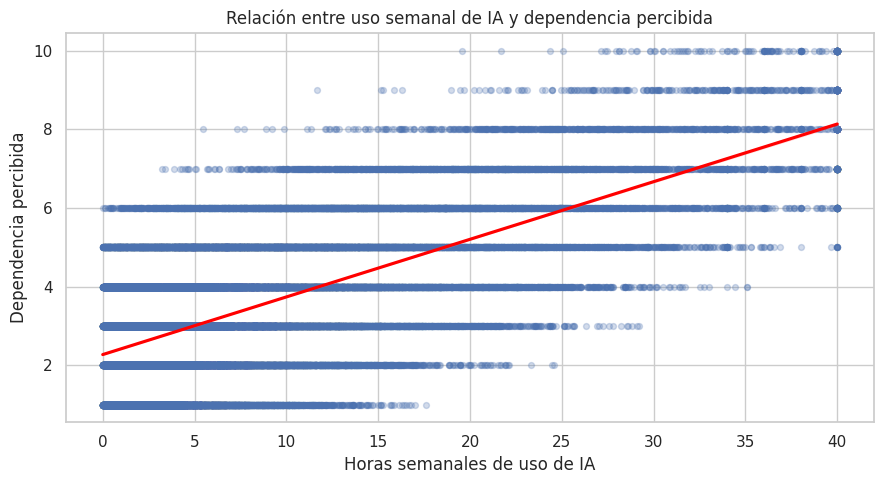

In [14]:
plt.figure(figsize=(9, 5))

sns.regplot(
    data=df,
    x="Weekly_GenAI_Hours",
    y="Perceived_AI_Dependency",
    scatter_kws={"alpha": 0.25, "s": 18},
    line_kws={"color": "red"}
)

plt.title("Relación entre uso semanal de IA y dependencia percibida")
plt.xlabel("Horas semanales de uso de IA")
plt.ylabel("Dependencia percibida")
plt.tight_layout()
plt.show()